# Assignment 3 - Handwritten Digit Classification using SVM

Classify handwritten digits (0-9) using linear and RBF-kernel SVMs.

*Dataset: scikit-learn `load_digits` (8 x 8 images, 64 features).*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

RANDOM_STATE = 42

## 1. Data understanding and cleaning

In [2]:
digits = load_digits()
X = digits.data
y = digits.target

print("Feature matrix shape:", X.shape)
print("Image shape:", digits.images.shape[1:])
print("Classes:", np.unique(y))
print("Pixel-value range:", X.min(), "to", X.max())
print("Missing values:", np.isnan(X).sum())

Feature matrix shape: (1797, 64)
Image shape: (8, 8)
Classes: [0 1 2 3 4 5 6 7 8 9]
Pixel-value range: 0.0 to 16.0
Missing values: 0


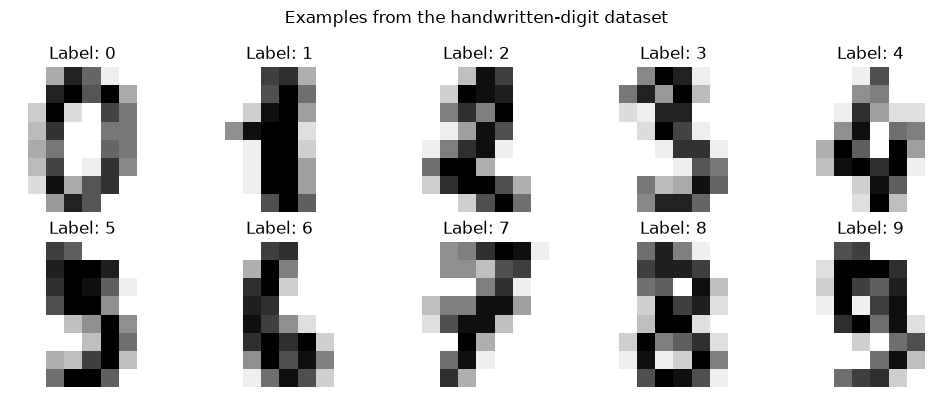

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), digits.images[:10], y[:10]):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.suptitle("Examples from the handwritten-digit dataset")
plt.tight_layout()
plt.show()

## 2. Data preparation

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Scaled training mean (first feature):", round(X_train_scaled[:, 0].mean(), 6))
print(
    "Scaled training standard deviation (first feature):",
    round(X_train_scaled[:, 0].std(), 6),
)

Training set: (1257, 64)
Test set: (540, 64)
Scaled training mean (first feature): 0.0
Scaled training standard deviation (first feature): 0.0


## 3. Linear SVM model

In [5]:
linear_model = SVC(kernel="linear", C=1.0)
linear_model.fit(X_train_scaled, y_train)
y_linear_pred = linear_model.predict(X_test_scaled)

linear_accuracy = accuracy_score(y_test, y_linear_pred)
print(f"Linear SVM accuracy: {linear_accuracy * 100:.2f}%")

Linear SVM accuracy: 97.96%


## 4. Non-linear RBF SVM model

In [6]:
rbf_model = SVC(kernel="rbf", C=10.0, gamma="scale")
rbf_model.fit(X_train_scaled, y_train)
y_rbf_pred = rbf_model.predict(X_test_scaled)

rbf_accuracy = accuracy_score(y_test, y_rbf_pred)
print(f"RBF SVM accuracy: {rbf_accuracy * 100:.2f}%")

RBF SVM accuracy: 98.15%


## 5. Hyperparameter tuning

In [7]:
tuning_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf")),
])

param_grid = {
    "svm__C": [1, 10, 30],
    "svm__gamma": ["scale", 0.001, 0.01],
}

grid_search = GridSearchCV(
    tuning_pipeline,
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_tuned_pred = best_model.predict(X_test)
tuned_accuracy = accuracy_score(y_test, y_tuned_pred)

print("Best parameters:", grid_search.best_params_)
print(f"Best cross-validation accuracy: {grid_search.best_score_ * 100:.2f}%")
print(f"Tuned RBF SVM test accuracy: {tuned_accuracy * 100:.2f}%")

Best parameters: {'svm__C': 10, 'svm__gamma': 'scale'}
Best cross-validation accuracy: 98.25%
Tuned RBF SVM test accuracy: 98.15%


## 6. Model evaluation

Classification report for the tuned RBF SVM:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        54
           1       0.95      0.98      0.96        55
           2       1.00      0.98      0.99        53
           3       1.00      1.00      1.00        55
           4       0.95      0.98      0.96        54
           5       1.00      0.98      0.99        55
           6       0.98      1.00      0.99        54
           7       0.96      1.00      0.98        54
           8       1.00      0.92      0.96        52
           9       0.98      0.96      0.97        54

    accuracy                           0.98       540
   macro avg       0.98      0.98      0.98       540
weighted avg       0.98      0.98      0.98       540



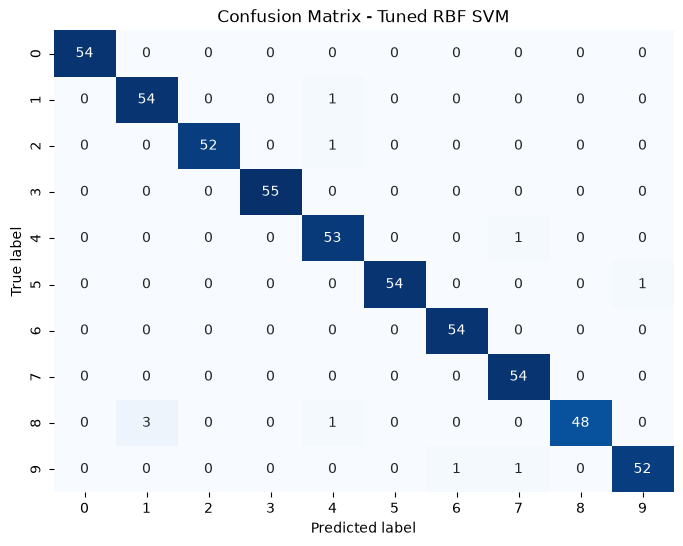

In [8]:
print("Classification report for the tuned RBF SVM:\n")
print(classification_report(y_test, y_tuned_pred))

confusion = confusion_matrix(y_test, y_tuned_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix - Tuned RBF SVM")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

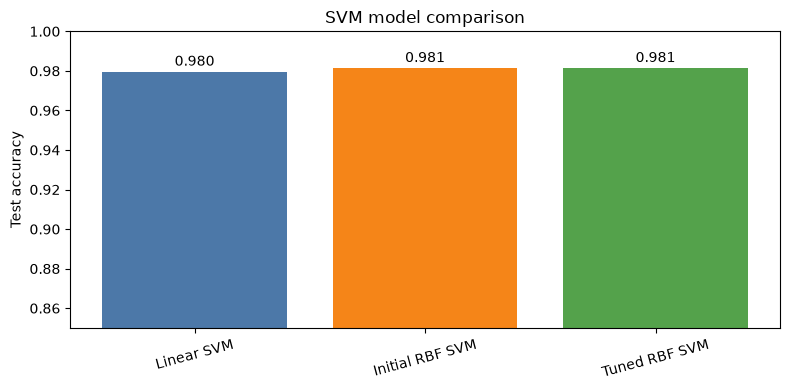

In [9]:
comparison = {
    "Linear SVM": linear_accuracy,
    "Initial RBF SVM": rbf_accuracy,
    "Tuned RBF SVM": tuned_accuracy,
}

plt.figure(figsize=(8, 4))
bars = plt.bar(
    comparison.keys(),
    comparison.values(),
    color=["#4c78a8", "#f58518", "#54a24b"],
)
plt.ylim(0.85, 1.0)
plt.ylabel("Test accuracy")
plt.title("SVM model comparison")
plt.xticks(rotation=15)
for bar, score in zip(bars, comparison.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.003,
        f"{score:.3f}",
        ha="center",
    )
plt.tight_layout()
plt.show()

## 7. Visualize predictions

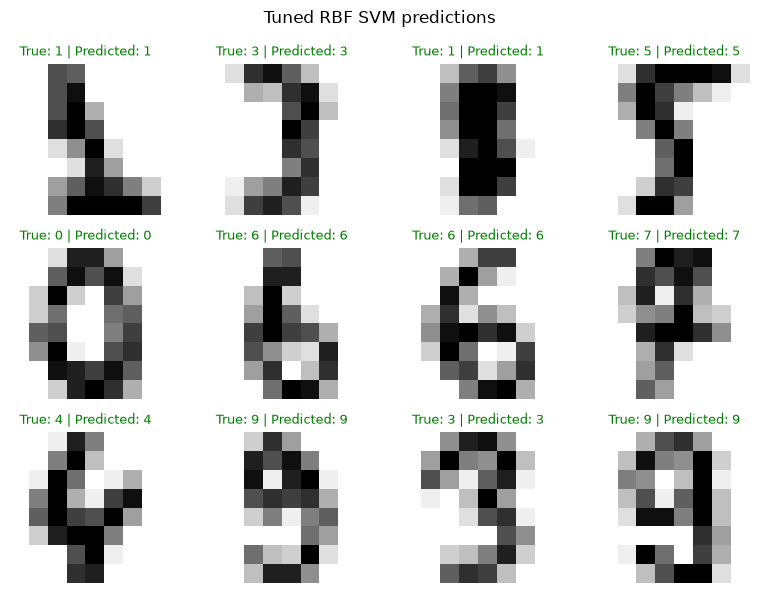

In [10]:
sample_count = 12
sample_indices = np.arange(sample_count)

fig, axes = plt.subplots(3, 4, figsize=(8, 6))
for ax, index in zip(axes.ravel(), sample_indices):
    ax.imshow(X_test[index].reshape(8, 8), cmap="gray_r")
    predicted = y_tuned_pred[index]
    actual = y_test[index]
    colour = "green" if predicted == actual else "red"
    ax.set_title(
        f"True: {actual} | Predicted: {predicted}",
        color=colour,
        fontsize=9,
    )
    ax.axis("off")

plt.suptitle("Tuned RBF SVM predictions")
plt.tight_layout()
plt.show()